## LOAN APPROVAL PREDICTION USING MACHINE LEARNING

#### IMPORT LIBRARIES

In [1]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns
import warnings 
warnings.filterwarnings('ignore')

#### LOAD DATASET

In [2]:
df = pd.read_csv("LoanUncleanedDataset.csv")

#We keep backup of the original data so we can compare before/after cleaning 
df_original = df.copy()
print(df_original.shape)

(10150, 12)


#### Shape of Original dataset

In [3]:
df.shape

(10150, 12)

In [4]:
df.head()

,Age,Monthly Income (Rupees),Guarantor Income (Rupees),Loan Amount (Rupees),Loan Duration (Month),CIBIL Score,Employment Years,Existing Loans,Rural,Semi-Urban,Urban,Loan Status
0,31.0,169174,45961.0,3015577.0,36.0,607,NaN,1.0,0,0,1,1
1,26.0,114926,77713.0,1298463.0,240.0,855,4.0,2.0,1,0,0,1
2,48.0,126126,0.0,1236702.0,120.0,NaN,4.0,2.0,0,1,0,1
3,62.0,48717,81296.0,NaN,240.0,474,NaN,4.0,0,1,0,0
4,50.0,118716,114583.0,4756617.0,24.0,593,1.0,0.0,0,1,0,0


In [5]:
df.tail()

,Age,Monthly Income (Rupees),Guarantor Income (Rupees),Loan Amount (Rupees),Loan Duration (Month),CIBIL Score,Employment Years,Existing Loans,Rural,Semi-Urban,Urban,Loan Status
10145,34.0,184564,26360.0,2431858.0,60.0,NaN,10.0,4.0,1,0,0,0
10146,63.0,84001,0.0,2272360.0,60.0,373,1.0,4.0,0,0,1,0
10147,39.0,159137,0.0,786900.0,60.0,781,1.0,3.0,0,0,1,1
10148,61.0,109120,117029.0,960219.0,240.0,754,6.0,0.0,0,1,0,1
10149,28.0,143773,0.0,3099213.0,NaN,451,4.0,0.0,0,0,1,0


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10150 entries, 0 to 10149
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Age                        9649 non-null   float64
 1   Monthly Income (Rupees)    9527 non-null   object 
 2   Guarantor Income (Rupees)  9744 non-null   float64
 3   Loan Amount (Rupees)       9644 non-null   float64
 4   Loan Duration (Month)      9846 non-null   float64
 5   CIBIL Score                9428 non-null   object 
 6   Employment Years           9541 non-null   float64
 7   Existing Loans             9745 non-null   float64
 8   Rural                      10150 non-null  int64  
 9   Semi-Urban                 10150 non-null  int64  
 10  Urban                      10150 non-null  int64  
 11  Loan Status                9848 non-null   object 
dtypes: float64(6), int64(3), object(3)
memory usage: 951.7+ KB


In [7]:
df.dtypes

Age                          float64
Monthly Income (Rupees)       object
Guarantor Income (Rupees)    float64
Loan Amount (Rupees)         float64
Loan Duration (Month)        float64
CIBIL Score                   object
Employment Years             float64
Existing Loans               float64
Rural                          int64
Semi-Urban                     int64
Urban                          int64
Loan Status                   object
dtype: object

In [8]:
df.describe()

,Age,Guarantor Income (Rupees),Loan Amount (Rupees),Loan Duration (Month),Employment Years,Existing Loans,Rural,Semi-Urban,Urban
count,9649.000000,9744.000000,9.644000e+03,9846.000000,9541.000000,9745.00000,10150.000000,10150.000000,10150.000000
mean,44.480257,32618.437808,2.512947e+06,124.219378,4.948538,1.97609,0.298916,0.398522,0.302562
std,42.911014,46979.538903,1.448425e+06,109.896050,8.987784,1.42410,0.457806,0.489618,0.459390
min,-5.000000,0.000000,-4.471444e+06,12.000000,-5.000000,0.00000,0.000000,0.000000,0.000000
25%,32.000000,0.000000,1.306001e+06,36.000000,1.000000,1.00000,0.000000,0.000000,0.000000
50%,42.000000,0.000000,2.512410e+06,84.000000,3.000000,2.00000,0.000000,0.000000,0.000000
75%,53.000000,64166.000000,3.755449e+06,180.000000,7.000000,3.00000,1.000000,1.000000,1.000000
max,999.000000,149994.000000,4.999929e+06,360.000000,200.000000,4.00000,1.000000,1.000000,1.000000


#### Shows statistical information from all data

In [9]:
df.describe(include='all')

,Age,Monthly Income (Rupees),Guarantor Income (Rupees),Loan Amount (Rupees),Loan Duration (Month),CIBIL Score,Employment Years,Existing Loans,Rural,Semi-Urban,Urban,Loan Status
count,9649.000000,9527,9744.000000,9.644000e+03,9846.000000,9428,9541.000000,9745.00000,10150.000000,10150.000000,10150.000000,9848
unique,NaN,9051,NaN,NaN,NaN,607,NaN,NaN,NaN,NaN,NaN,10
top,NaN,not provided,NaN,NaN,NaN,383,NaN,NaN,NaN,NaN,NaN,0
freq,NaN,27,NaN,NaN,NaN,31,NaN,NaN,NaN,NaN,NaN,4926
mean,44.480257,NaN,32618.437808,2.512947e+06,124.219378,NaN,4.948538,1.97609,0.298916,0.398522,0.302562,NaN
std,42.911014,NaN,46979.538903,1.448425e+06,109.896050,NaN,8.987784,1.42410,0.457806,0.489618,0.459390,NaN
min,-5.000000,NaN,0.000000,-4.471444e+06,12.000000,NaN,-5.000000,0.00000,0.000000,0.000000,0.000000,NaN
25%,32.000000,NaN,0.000000,1.306001e+06,36.000000,NaN,1.000000,1.00000,0.000000,0.000000,0.000000,NaN
50%,42.000000,NaN,0.000000,2.512410e+06,84.000000,NaN,3.000000,2.00000,0.000000,0.000000,0.000000,NaN
75%,53.000000,NaN,64166.000000,3.755449e+06,180.000000,NaN,7.000000,3.00000,1.000000,1.000000,1.000000,NaN


#### Desribe about missing values in each cell individually

In [10]:
df.isnull().sum()

Age                          501
Monthly Income (Rupees)      623
Guarantor Income (Rupees)    406
Loan Amount (Rupees)         506
Loan Duration (Month)        304
CIBIL Score                  722
Employment Years             609
Existing Loans               405
Rural                          0
Semi-Urban                     0
Urban                          0
Loan Status                  302
dtype: int64

#### Correlation before data cleaning

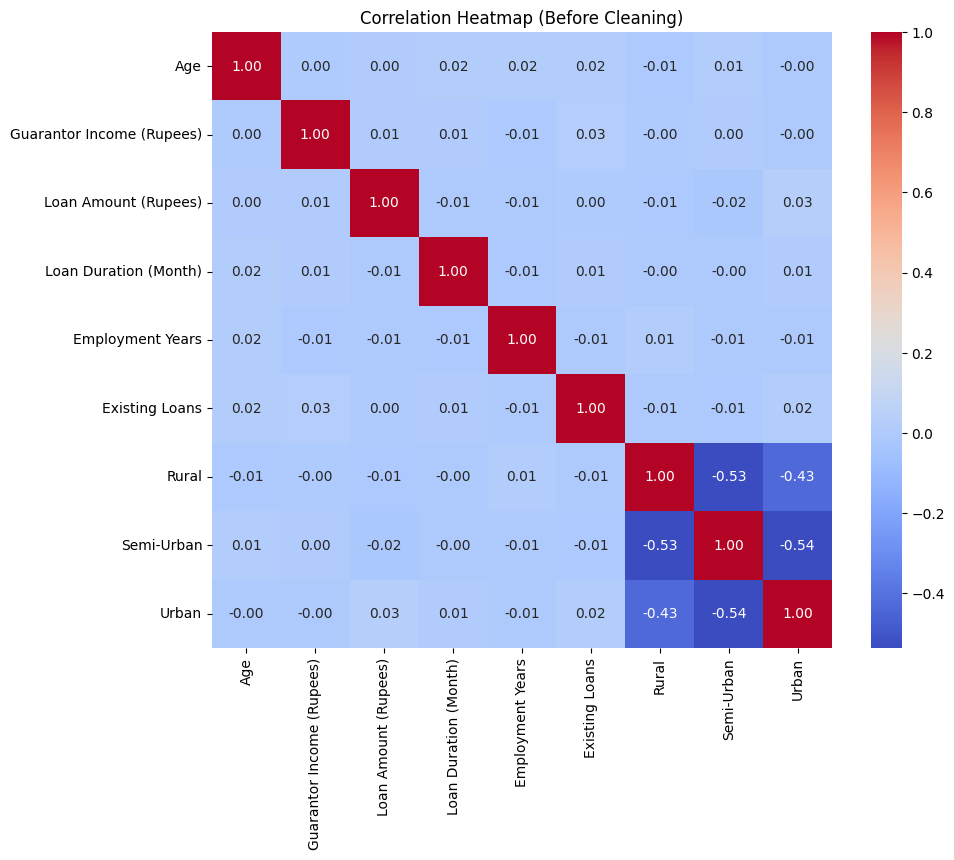

In [11]:
# It tells us how much two columns are related to each other 
# If value close to +1 two feature respective of each other increase together 
# If value close to -1 one feature increases and other decreases 
plt.figure(figsize=(10, 8))
sns.heatmap(df_original.corr(numeric_only=True), annot=True, fmt='.2f', cmap='coolwarm') # annot = 2 represents numbers are placed between boxes 
plt.title("Correlation Heatmap (Before Cleaning)")
plt.show()

#### Covariance before data cleaning

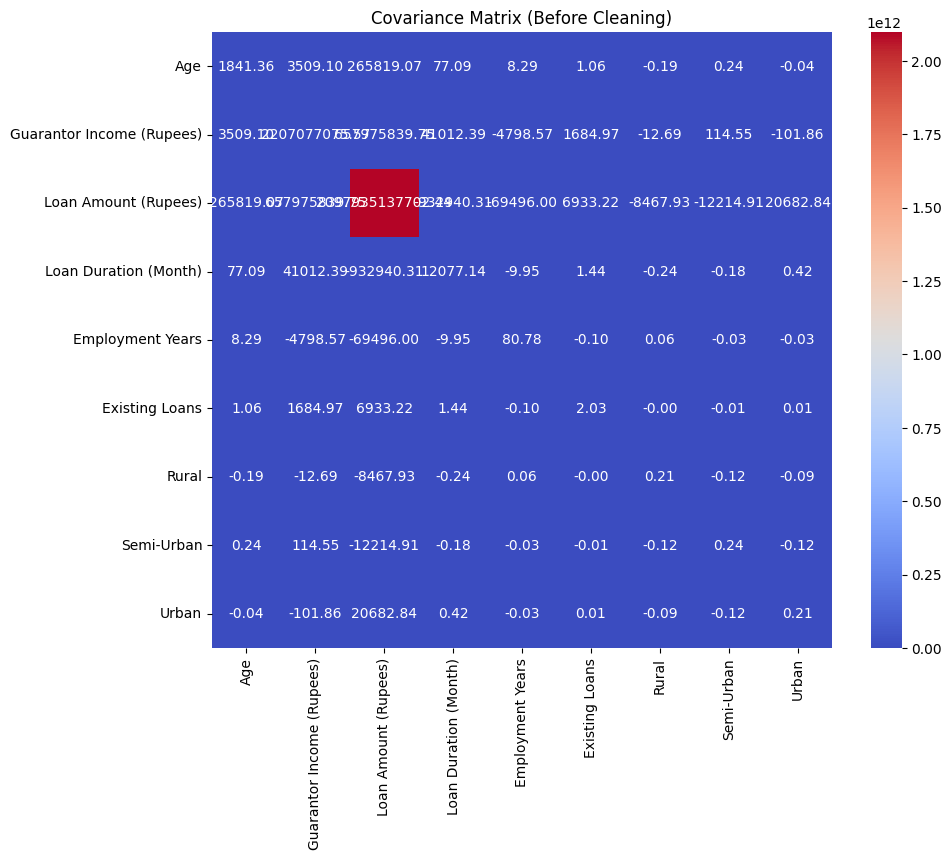

In [12]:
# It tells us the direction of relationship 
plt.figure(figsize=(10, 8))
sns.heatmap(df_original.cov(numeric_only=True), annot=True, fmt='.2f', cmap='coolwarm')
plt.title("Covariance Matrix (Before Cleaning)")
plt.show()

##### We checked what percentage of each column was missing

In [13]:
print("BEFORE CLEANING:")
(df.isnull().sum() / len(df) * 100).round(2).sort_values(ascending=False)

BEFORE CLEANING:


CIBIL Score                  7.11
Monthly Income (Rupees)      6.14
Employment Years             6.00
Loan Amount (Rupees)         4.99
Age                          4.94
Guarantor Income (Rupees)    4.00
Existing Loans               3.99
Loan Duration (Month)        3.00
Loan Status                  2.98
Rural                        0.00
Semi-Urban                   0.00
Urban                        0.00
dtype: float64

In [14]:
print(df.columns)

Index(['Age', 'Monthly Income (Rupees)', 'Guarantor Income (Rupees)',
       'Loan Amount (Rupees)', 'Loan Duration (Month)', 'CIBIL Score',
       'Employment Years', 'Existing Loans', 'Rural', 'Semi-Urban', 'Urban',
       'Loan Status'],
      dtype='object')


## DATA CLEANING

#### Cleaning for Age Column

In [15]:
invalid_age = df[(df['Age'] < 18) | (df['Age'] > 80)]

print("Invalid Age Values:")
print(invalid_age['Age'].unique())

df['Age'] = pd.to_numeric(df['Age'],errors='coerce')
# convert all the values to numeric and if the value is not numeric like abc, convert it into NaN
df = df[(df['Age']>=18) & (df['Age']<=80)]
print("Shape after cleaning: ", df.shape)

Invalid Age Values:
[ -5.   0. 150. 999. 200.]
Shape after cleaning:  (9569, 12)


#### For Monthly Income

In [16]:
df['Monthly Income (Rupees)'] = pd.to_numeric(df['Monthly Income (Rupees)'], errors='coerce')
invalid_income = df[(df['Monthly Income (Rupees)'] <= 0) | (df['Monthly Income (Rupees)'].isnull())]
print("Invalid Monthly Income Values:")
print(invalid_income['Monthly Income (Rupees)'].unique())

# Clean
df = df[df['Monthly Income (Rupees)'] > 0]
df = df.dropna(subset=['Monthly Income (Rupees)']) # it removes rows where income is NaN
print("Shape after cleaning:", df.shape)

Invalid Monthly Income Values:
[    nan -5.e+03 -1.e+00  0.e+00]
Shape after cleaning: (8875, 12)


#### Guarantor Income

In [17]:
df['Guarantor Income (Rupees)'] = pd.to_numeric(df['Guarantor Income (Rupees)'], errors='coerce')
invalid_coapplicant = df[(df['Guarantor Income (Rupees)'] < 0) | (df['Guarantor Income (Rupees)'].isnull())]
print("Invalid Gurantor Income Values:")
print(invalid_coapplicant['Guarantor Income (Rupees)'].unique())

df = df[df['Guarantor Income (Rupees)'] >= 0]
df = df.dropna(subset=['Guarantor Income (Rupees)'])
print("Shape after cleaning:", df.shape)

Invalid Gurantor Income Values:
[nan]
Shape after cleaning: (8522, 12)


#### For Loan Amount

In [18]:
df['Loan Amount (Rupees)'] = pd.to_numeric(df['Loan Amount (Rupees)'], errors='coerce')
invalid_loan = df[(df['Loan Amount (Rupees)'] <= 0) | (df['Loan Amount (Rupees)'].isnull())]
print("Invalid Loan Amount Values:")
print(invalid_loan['Loan Amount (Rupees)'].unique())

# Clean
df = df[df['Loan Amount (Rupees)'] > 0]
df = df.dropna(subset=['Loan Amount (Rupees)'])
print("Shape after cleaning:", df.shape)

Invalid Loan Amount Values:
[      nan  -270833. -1216602. -2357123. -1131426. -2797637. -2530174.
 -3019577.  -956050.  -378807. -2045523. -3162201. -4471444. -1792802.
 -4049089. -1652522. -3870183. -1365156. -3249699. -2760657. -1302521.
 -2968396. -4349726.  -415809. -3819395. -2743005. -4440812.  -443592.
  -374492.  -297541. -1095075. -2319862. -2666961. -3471014. -1038748.]
Shape after cleaning: (8060, 12)


#### For Loan Duration

In [19]:
df['Loan Duration (Month)'] = pd.to_numeric(df['Loan Duration (Month)'], errors='coerce')
invalid_duration = df[(df['Loan Duration (Month)'] <= 0) | (df['Loan Duration (Month)'].isnull())]
print("Invalid Loan Duration Values:")
print(invalid_duration['Loan Duration (Month)'].unique())

# Clean
df = df[df['Loan Duration (Month)'] > 0]
df = df.dropna(subset=['Loan Duration (Month)'])
print("Shape after cleaning:", df.shape)

Invalid Loan Duration Values:
[nan]
Shape after cleaning: (7807, 12)


#### For CIBIL Score

In [20]:
df['CIBIL Score'] = pd.to_numeric(df['CIBIL Score'], errors='coerce')
invalid_cibil = df[(df['CIBIL Score'] < 300) | (df['CIBIL Score'] > 900) | (df['CIBIL Score'].isnull())]
print("Invalid CIBIL Score Values:")
print(invalid_cibil['CIBIL Score'].unique())

# Clean
df = df[(df['CIBIL Score'] >= 300) & (df['CIBIL Score'] <= 900)]
df = df.dropna(subset=['CIBIL Score'])
print("Shape after cleaning:", df.shape)

Invalid CIBIL Score Values:
[  nan 1200. -100.    0. 1000.]
Shape after cleaning: (7154, 12)


#### Employment Years

In [21]:
df['Employment Years'] = pd.to_numeric(df['Employment Years'], errors='coerce')
invalid_emp = df[(df['Employment Years'] < 0) | (df['Employment Years'].isnull())]
print("Invalid Employment Years Values:")
print(invalid_emp['Employment Years'].unique())

# Clean
df = df[df['Employment Years'] >= 0]
df = df.dropna(subset=['Employment Years'])
print("Shape after cleaning:", df.shape)

Invalid Employment Years Values:
[nan -1. -5.]
Shape after cleaning: (6698, 12)


#### Existing Loans

In [22]:
df['Existing Loans'] = pd.to_numeric(df['Existing Loans'], errors='coerce')
invalid_loans = df[(df['Existing Loans'] < 0) | (df['Existing Loans'].isnull())]
print("Invalid Existing Loans Values:")
print(invalid_loans['Existing Loans'].unique())

# Clean
df = df[df['Existing Loans'] >= 0]
df = df.dropna(subset=['Existing Loans'])
print("Shape after cleaning:", df.shape)

Invalid Existing Loans Values:
[nan]
Shape after cleaning: (6428, 12)


#### Loan Status

In [23]:
print("Invalid Loan Status Values:")
print(df['Loan Status'].unique())

# Clean - map all variations to 0 or 1
loan_map = {
    '1'      : 1,  '0'      : 0,
     1       : 1,   0       : 0,
    'YES'    : 1,  'NO'     : 0,
    'Yes'    : 1,  'No'     : 0,
    'approve': 1,  'reject' : 0,
    'one'    : 1,  'zero'   : 0
}

# replace the value using dictionary and if outside that then convert into NaN 
df['Loan Status'] = df['Loan Status'].map(loan_map)
df = df.dropna(subset=['Loan Status'])

#convert all the values to integer that is either 1 or 0
df['Loan Status'] = df['Loan Status'].astype(int)

print("Loan Status after cleaning:")
print(df['Loan Status'].value_counts())
print("Shape after cleaning:", df.shape)

Invalid Loan Status Values:
['1' '0' nan 'YES' 'zero' 'NO' 'reject' 'one' 'Yes' 'approve' 'No']
Loan Status after cleaning:
Loan Status
1    3121
0    3118
Name: count, dtype: int64
Shape after cleaning: (6239, 12)


### ORIGINAL SHAPE, CLEANED SHAPE AND THE ROWS REMOVED AFTER CLEANING

In [24]:
print("Original Shape :", df_original.shape)
print("Cleaned Shape  :", df.shape)
print("Rows Removed   :", df_original.shape[0] - df.shape[0])

Original Shape : (10150, 12)
Cleaned Shape  : (6239, 12)
Rows Removed   : 3911


In [25]:
print("AFTER COLUMN CLEANING:")
(df.isnull().sum() / len(df) * 100).round(2).sort_values(ascending=False)

AFTER COLUMN CLEANING:


Age                          0.0
Monthly Income (Rupees)      0.0
Guarantor Income (Rupees)    0.0
Loan Amount (Rupees)         0.0
Loan Duration (Month)        0.0
CIBIL Score                  0.0
Employment Years             0.0
Existing Loans               0.0
Rural                        0.0
Semi-Urban                   0.0
Urban                        0.0
Loan Status                  0.0
dtype: float64

In [26]:
# Even after cleaning, some missing values might still be there. Instead of removing those rows we fill them with the median value of that column 
from sklearn.impute import SimpleImputer

num_cols = ['Monthly Income (Rupees)', 'Guarantor Income (Rupees)', 'Loan Amount (Rupees)',
            'Loan Duration (Month)', 'CIBIL Score', 
            'Employment Years', 'Existing Loans']

# Fill missing values with median
imputer = SimpleImputer(strategy='median')
# fit_transform = calculates median of each column and replaces missing value with those medians 
df[num_cols] = imputer.fit_transform(df[num_cols])

print("Missing values after imputation:")
print(df.isnull().sum())

Missing values after imputation:
Age                          0
Monthly Income (Rupees)      0
Guarantor Income (Rupees)    0
Loan Amount (Rupees)         0
Loan Duration (Month)        0
CIBIL Score                  0
Employment Years             0
Existing Loans               0
Rural                        0
Semi-Urban                   0
Urban                        0
Loan Status                  0
dtype: int64


### Missing % after imputation

In [28]:
print("AFTER IMPUTATION: ")
(df.isnull().sum()/len(df)*100).round(2).sort_values(ascending=False)

AFTER IMPUTATION: 


Age                          0.0
Monthly Income (Rupees)      0.0
Guarantor Income (Rupees)    0.0
Loan Amount (Rupees)         0.0
Loan Duration (Month)        0.0
CIBIL Score                  0.0
Employment Years             0.0
Existing Loans               0.0
Rural                        0.0
Semi-Urban                   0.0
Urban                        0.0
Loan Status                  0.0
dtype: float64

In [29]:
df.describe()

,Age,Monthly Income (Rupees),Guarantor Income (Rupees),Loan Amount (Rupees),Loan Duration (Month),CIBIL Score,Employment Years,Existing Loans,Rural,Semi-Urban,Urban,Loan Status
count,6239.000000,6.239000e+03,6239.000000,6.239000e+03,6239.000000,6239.000000,6239.000000,6239.000000,6239.000000,6239.000000,6239.000000,6239.00000
mean,42.442859,2.991321e+05,32151.865363,2.525017e+06,124.837314,597.201635,4.905273,1.968264,0.303414,0.396217,0.300369,0.50024
std,12.565171,4.377411e+06,46769.010410,1.415600e+06,109.366917,172.957370,9.141079,1.431660,0.459769,0.489150,0.458455,0.50004
min,21.000000,1.500500e+04,0.000000,5.128200e+04,12.000000,300.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,32.000000,6.059900e+04,0.000000,1.306658e+06,36.000000,450.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.00000
50%,42.000000,1.074790e+05,0.000000,2.499750e+06,84.000000,593.000000,3.000000,2.000000,0.000000,0.000000,0.000000,1.00000
75%,53.000000,1.530885e+05,63076.000000,3.753528e+06,180.000000,748.000000,7.000000,3.000000,1.000000,1.000000,1.000000,1.00000
max,64.000000,1.000000e+08,149994.000000,4.999898e+06,360.000000,899.000000,200.000000,4.000000,1.000000,1.000000,1.000000,1.00000


#### OUTLIER DETECTION

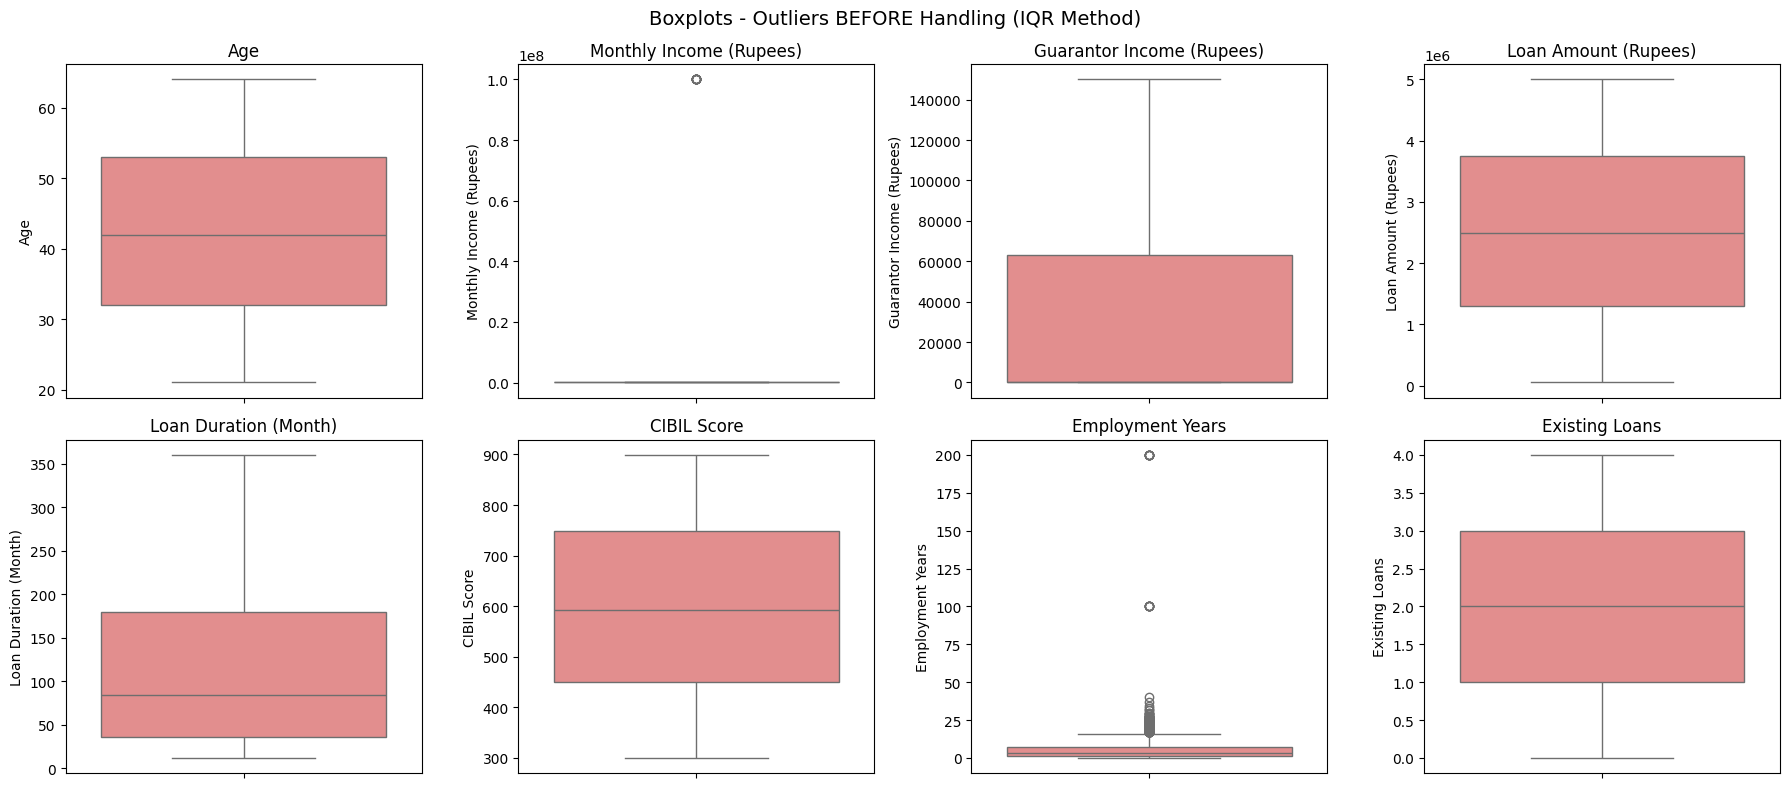

In [30]:
# Outliers - value that is extremely different from the rest 
num_cols = ['Age', 'Monthly Income (Rupees)', 'Guarantor Income (Rupees)', 'Loan Amount (Rupees)',
            'Loan Duration (Month)', 'CIBIL Score', 'Employment Years', 'Existing Loans']

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten() # converts a 2d array of plots into 1d array 

for i, col in enumerate(num_cols):
    sns.boxplot(y=df[col], ax=axes[i], color='lightcoral')
    axes[i].set_title(col)

# Boxplot shows the spread of data and highlight outliers as dots above/below the box 
plt.suptitle("Boxplots - Outliers BEFORE Handling (IQR Method)", fontsize=14)
plt.tight_layout()
plt.show()

### Removing outliers 

In [31]:
num_cols = [
    'Age',
    'Monthly Income (Rupees)',
    'Guarantor Income (Rupees)',
    'Loan Amount (Rupees)',
    'Loan Duration (Month)',
    'CIBIL Score',
    'Employment Years',
    'Existing Loans'
]

# IQR _ inter quartile range which is the middle of data . 
for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    df = df[(df[col] >= lower) & (df[col] <= upper)]

print("Shape after removing all outliers:", df.shape)

Shape after removing all outliers: (5997, 12)


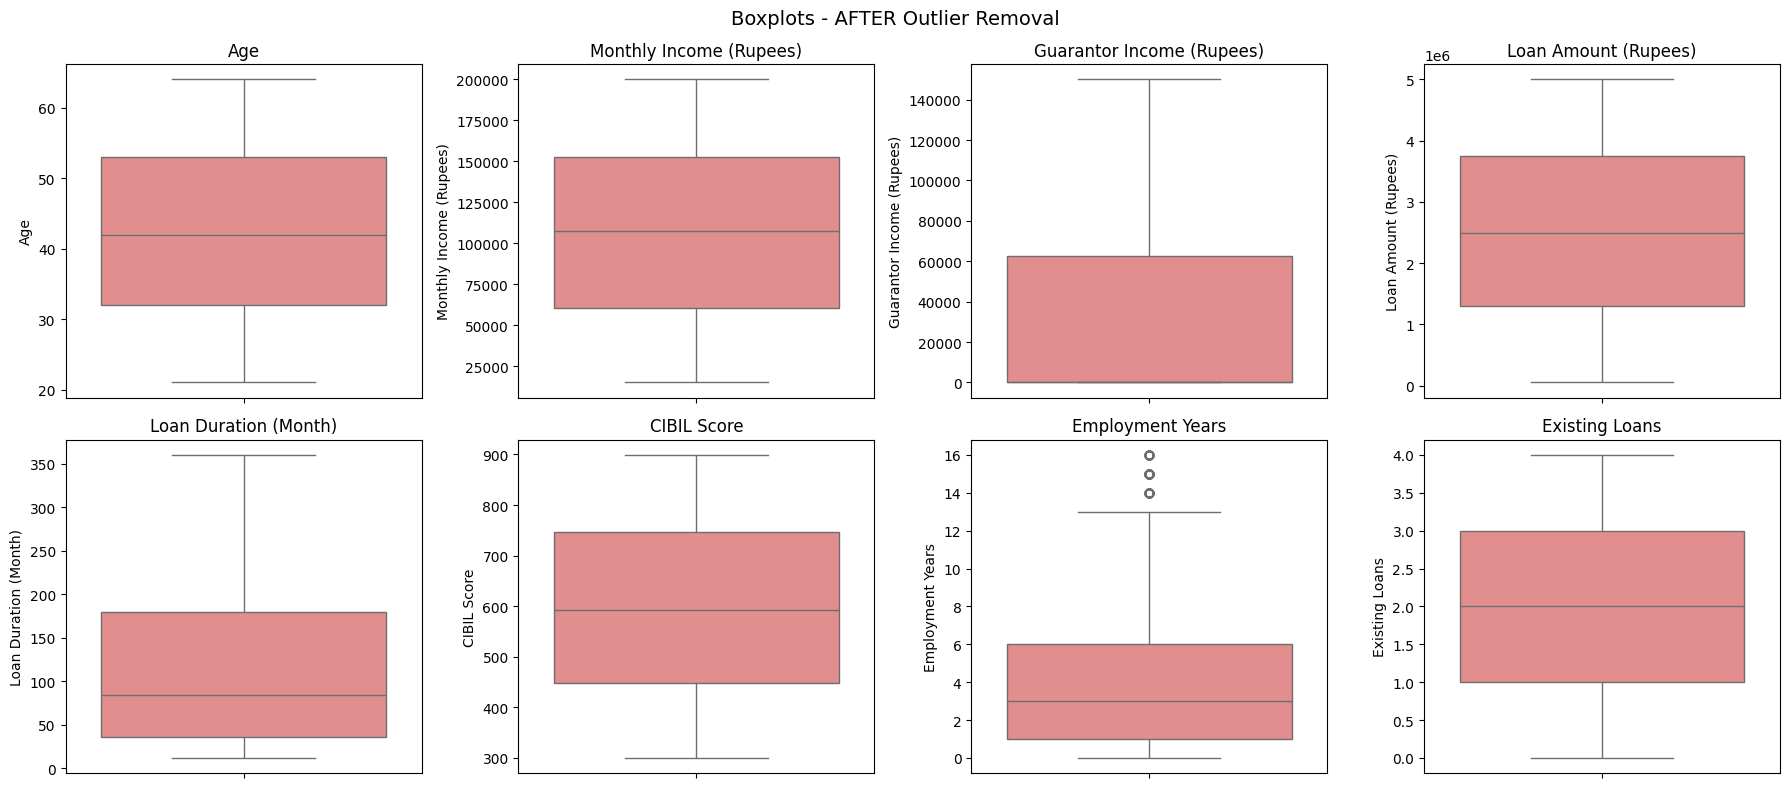

In [32]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))

for i, col in enumerate(num_cols):
    sns.boxplot(y=df[col], ax=axes[i//4, i%4], color='lightcoral')
    axes[i//4, i%4].set_title(col)

plt.suptitle("Boxplots - AFTER Outlier Removal", fontsize=14)
plt.tight_layout()
plt.show()

In [33]:
print(df.columns.tolist())

['Age', 'Monthly Income (Rupees)', 'Guarantor Income (Rupees)', 'Loan Amount (Rupees)', 'Loan Duration (Month)', 'CIBIL Score', 'Employment Years', 'Existing Loans', 'Rural', 'Semi-Urban', 'Urban', 'Loan Status']


In [34]:
print("Current columns:", df.columns.tolist())

#### Dropping Rural Column (Avoiding Dummy Variable Trap)
# If Urban=0 and Semi-Urban=0, we already know it is Rural so Rural column gives no new information — it is redundant

df = df.drop(columns=['Rural'])
print()
print("Columns after dropping Rural:")
print(df.columns.tolist())

Current columns: ['Age', 'Monthly Income (Rupees)', 'Guarantor Income (Rupees)', 'Loan Amount (Rupees)', 'Loan Duration (Month)', 'CIBIL Score', 'Employment Years', 'Existing Loans', 'Rural', 'Semi-Urban', 'Urban', 'Loan Status']

Columns after dropping Rural:
['Age', 'Monthly Income (Rupees)', 'Guarantor Income (Rupees)', 'Loan Amount (Rupees)', 'Loan Duration (Month)', 'CIBIL Score', 'Employment Years', 'Existing Loans', 'Semi-Urban', 'Urban', 'Loan Status']


In [35]:
print("Final Shape after cleaning the data and removing outliers:",df.shape)

Final Shape after cleaning the data and removing outliers: (5997, 11)


#### Correlation after data cleaning

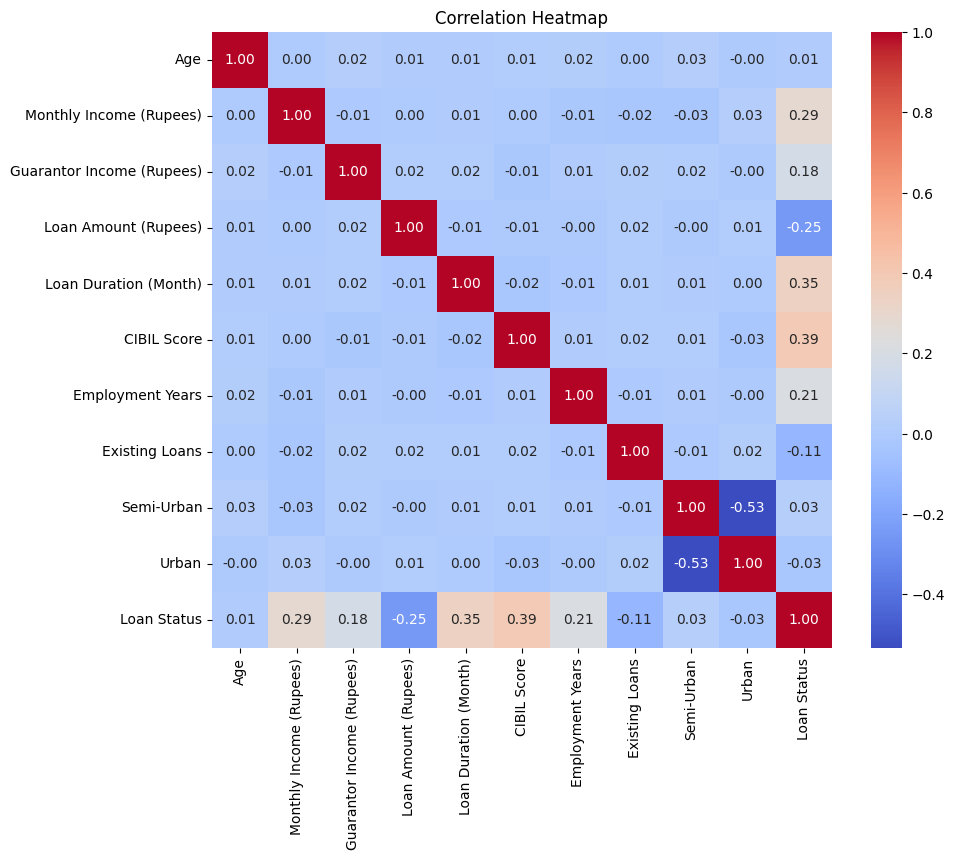

In [36]:
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title("Correlation Heatmap")
plt.show()

#### CoVariance after data cleaning

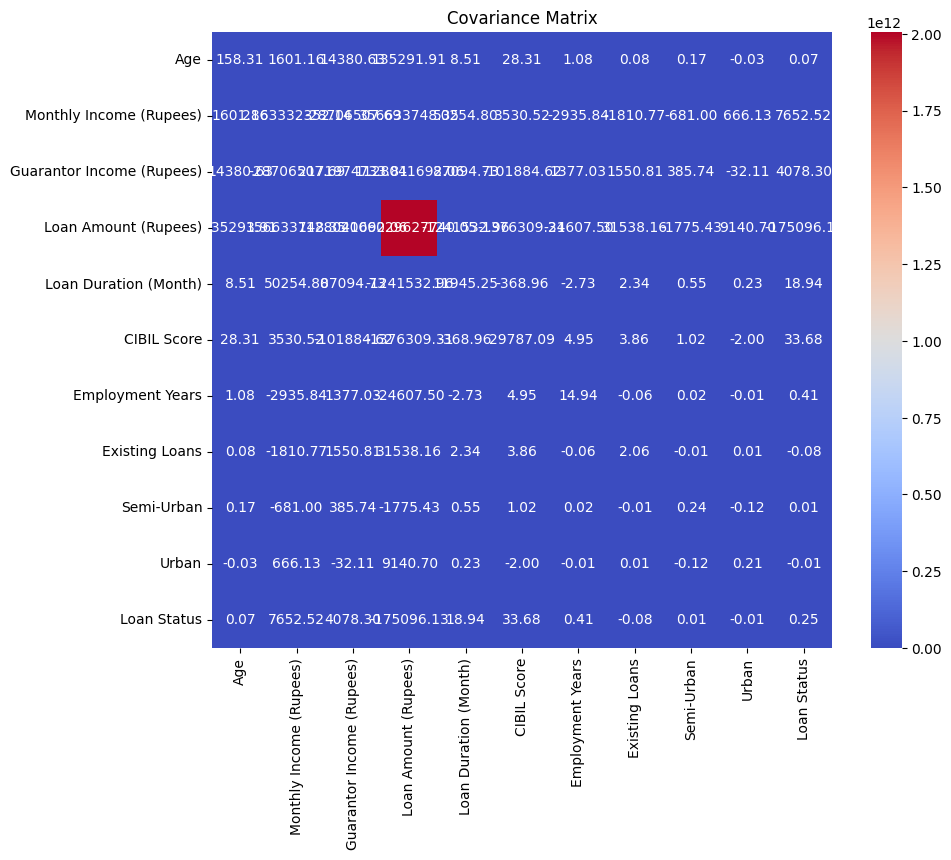

In [37]:
plt.figure(figsize=(10, 8))
sns.heatmap(df.cov(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title("Covariance Matrix")
plt.show()

#### Count Plot of Loan status

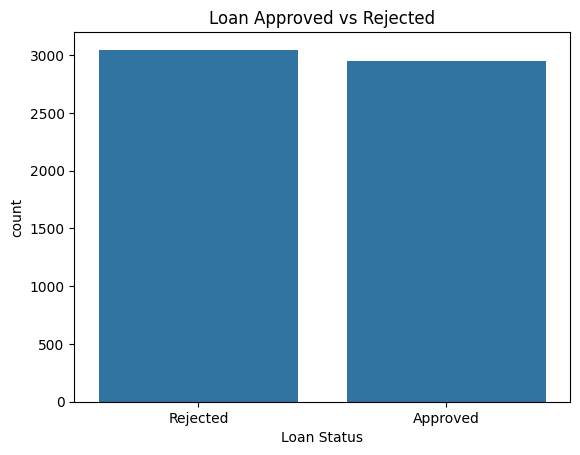

In [38]:
sns.countplot(data=df, x='Loan Status')
plt.title("Loan Approved vs Rejected")
plt.xticks([0, 1], ['Rejected', 'Approved'])
plt.show()

#### How CIBIL Score affects Loan Status

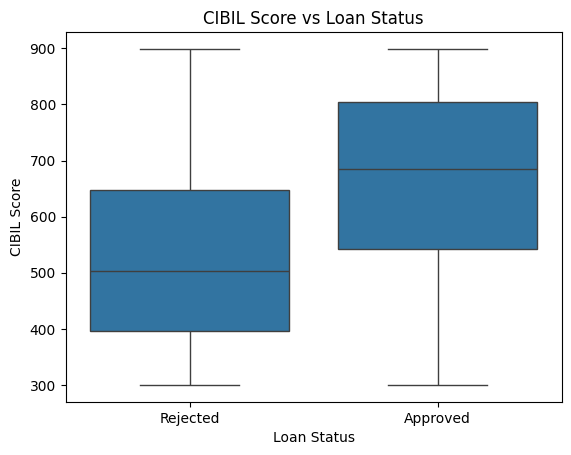

In [39]:
sns.boxplot(data=df, x='Loan Status', y='CIBIL Score')
plt.title("CIBIL Score vs Loan Status")
plt.xticks([0, 1], ['Rejected', 'Approved'])
plt.show()

#### Age vs Loan Status

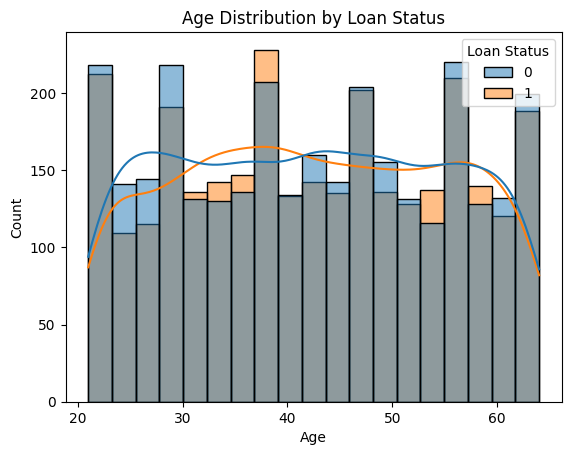

In [40]:
sns.histplot(data=df, x='Age', hue='Loan Status', kde=True)
plt.title("Age Distribution by Loan Status")
plt.show()

#### Class Imbalance check + Fix

Class Distribution (Before Balancing):
Loan Status
0    3046
1    2951
Name: count, dtype: int64

Percentage:
Loan Status
0    50.79
1    49.21
Name: count, dtype: float64


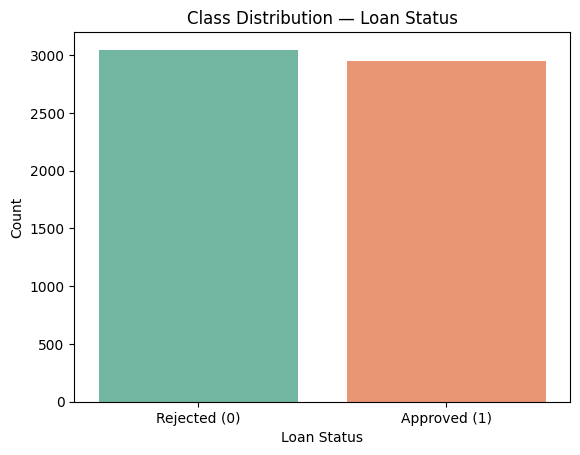

In [41]:
# Class Imbalance = one class has way more data than the other which makes model biased towards majority class 
# The count and % tells us how imbalanced our data is 
print("Class Distribution (Before Balancing):")
print(df['Loan Status'].value_counts()) #count number of samples in each class 
print()
print("Percentage:")
print((df['Loan Status'].value_counts() / len(df) * 100).round(2))

sns.countplot(data=df, x='Loan Status', palette='Set2')
plt.title("Class Distribution — Loan Status")
plt.xticks([0, 1], ['Rejected (0)', 'Approved (1)'])
plt.ylabel("Count")
plt.show()

#### Feature Scaling + Train Test split + Logistic Regression

In [42]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

X = df.drop('Loan Status', axis=1)
y = df['Loan Status']

# We split first so that scaling parameters (mean, std) are learned only from training data and then applied to test data  
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Standard Scaler - different columns have different ranges so scaler brings all columns to the same scale so no column dominates the model 
# Convert features to same scale where mean = 0 and std = 1
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test  = scaler.transform(X_test)

# logistic Regression - It predicts probability 
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

# Accuracy on training data 
print("Training Accuracy:", model.score(X_train, y_train))
# Accuracy on unseen(testing) data
print("Testing Accuracy :", model.score(X_test,  y_test))

Training Accuracy: 0.8530331457160726
Testing Accuracy : 0.8641666666666666


### DummyClassifier - Our model is better than random guessing

In [43]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, classification_report

# Dummy Classifier - it always predicts the most common class the one that appeared most in training 
dummy = DummyClassifier(strategy='most_frequent')   # predicts majority class

# trains dummy model 
dummy.fit(X_train, y_train)
# make predictions on test data 
y_pred_dummy = dummy.predict(X_test)

print("Dummy Classifier Accuracy:", accuracy_score(y_test, y_pred_dummy))
print(classification_report(y_test, y_pred_dummy))

Dummy Classifier Accuracy: 0.49083333333333334
              precision    recall  f1-score   support

           0       0.49      1.00      0.66       589
           1       0.00      0.00      0.00       611

    accuracy                           0.49      1200
   macro avg       0.25      0.50      0.33      1200
weighted avg       0.24      0.49      0.32      1200



#### CROSS VALIDATION SCORE 

In [44]:
from sklearn.model_selection import cross_val_score

# Cross Validation Score - splits training data into given parts . 
# It trains 5 times, each time testing on a different part where we get 5 accuracy score and then average 
cv_scores = cross_val_score(model, X_train, y_train, cv=5)

print("CV Scores:", cv_scores)
print("Mean CV Score:", cv_scores.mean())

CV Scores: [0.85104167 0.85729167 0.84671533 0.85088634 0.85088634]
Mean CV Score: 0.8513642683350712


#### PIPELINE

In [45]:
from sklearn.pipeline import Pipeline

# Pipeline - it chains multiple steps together 
pipeline = Pipeline([
    ('scaler', StandardScaler()), # normalize features
    ('model', LogisticRegression())
])

cv_scores = cross_val_score(pipeline, X, y, cv=5)

print("CV Scores:", cv_scores)
print("Mean CV Score:", cv_scores.mean())

CV Scores: [0.865      0.86083333 0.85738115 0.83486239 0.85321101]
Mean CV Score: 0.8542575757575758


#### Bias/Variance TradeOff

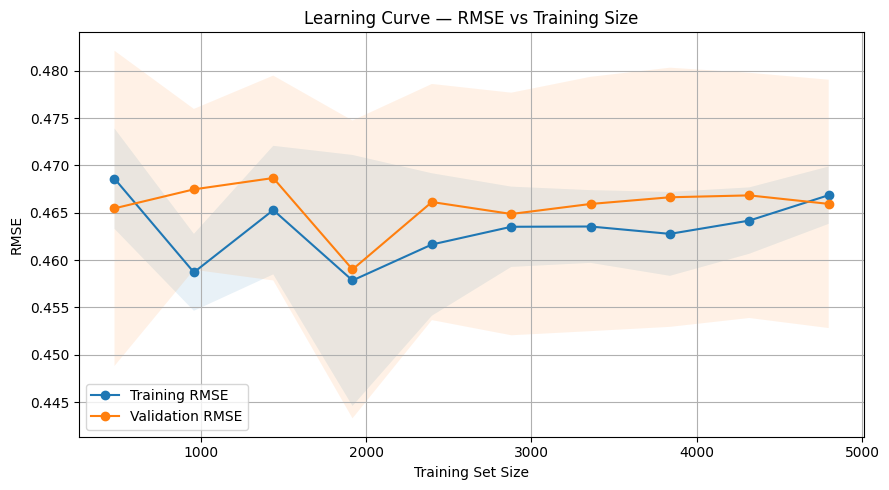

In [46]:
from sklearn.model_selection import learning_curve

# Use negative MSE because sklearn uses "higher is better"
train_sizes, train_scores, val_scores = learning_curve(
    LogisticRegression(max_iter=1000),
    X, y,
    cv=5,
    train_sizes=np.linspace(0.1, 1.0, 10),
    scoring='neg_mean_squared_error'
)

# Convert negative MSE to RMSE
train_rmse = np.sqrt(-train_scores)
val_rmse   = np.sqrt(-val_scores)

# Mean and std
train_mean = train_rmse.mean(axis=1)
train_std  = train_rmse.std(axis=1)
val_mean   = val_rmse.mean(axis=1)
val_std    = val_rmse.std(axis=1)

# Plot
plt.figure(figsize=(9, 5))
plt.plot(train_sizes, train_mean, 'o-', label='Training RMSE')
plt.plot(train_sizes, val_mean, 'o-', label='Validation RMSE')

plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.1)
plt.fill_between(train_sizes, val_mean - val_std, val_mean + val_std, alpha=0.1)

plt.title("Learning Curve — RMSE vs Training Size")
plt.xlabel("Training Set Size")
plt.ylabel("RMSE")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

#### Regularization Comparison (L1 vs L2)

Regularization Comparison:
---------------------------------------------
No Regularization         | Train: 0.8530 | Test: 0.8642
L2 Ridge (default)        | Train: 0.8530 | Test: 0.8642
L1 Lasso                  | Train: 0.8530 | Test: 0.8650


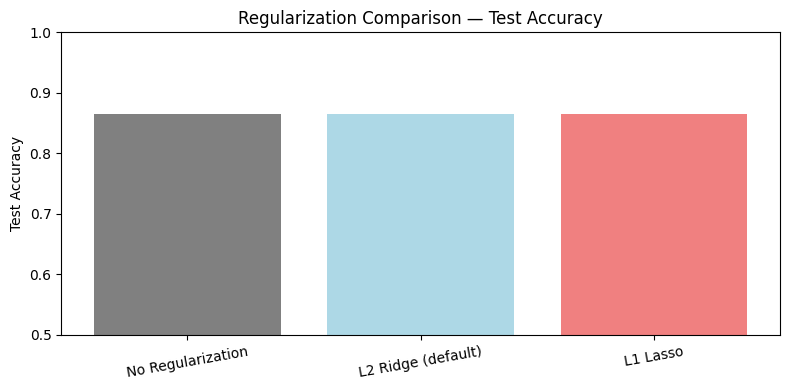

In [47]:
# Regularization = technique to prevent overfitting
# L1 (Lasso)  = makes some feature weights exactly 0 (removes features)
# L2 (Ridge)  = shrinks all weights but keeps all features
# C = inverse of regularization strength (smaller C = more regularization)
reg_results = {}

configs = {
    "No Regularization" : LogisticRegression(penalty=None,  max_iter=1000, solver='lbfgs'),
    "L2 Ridge (default)": LogisticRegression(penalty='l2',  max_iter=1000, solver='lbfgs'),
    "L1 Lasso"          : LogisticRegression(penalty='l1',  max_iter=1000, solver='liblinear'),
}

print("Regularization Comparison:")
print("-" * 45)
for name, reg_model in configs.items():
    reg_model.fit(X_train, y_train)
    train_acc = reg_model.score(X_train, y_train)
    test_acc  = reg_model.score(X_test,  y_test)
    reg_results[name] = test_acc
    print(f"{name:<25} | Train: {train_acc:.4f} | Test: {test_acc:.4f}")

# Plot
plt.figure(figsize=(8, 4))
plt.bar(reg_results.keys(), reg_results.values(), color=['gray', 'lightblue', 'lightcoral'])
plt.title("Regularization Comparison — Test Accuracy")
plt.ylabel("Test Accuracy")
plt.ylim(0.5, 1.0)
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()

#### Confusion Matrix 

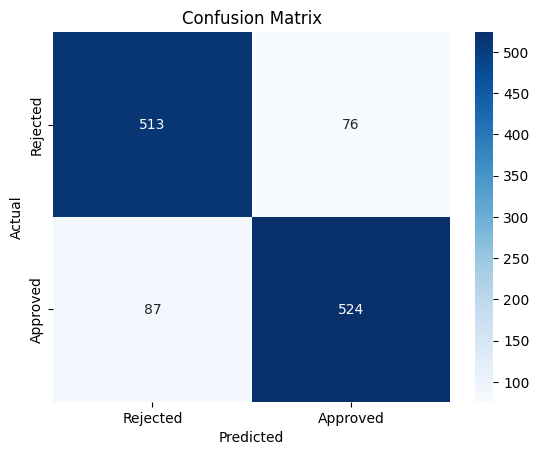

In [48]:
# To check how correct our model predicts 
from sklearn.metrics import confusion_matrix

# Model makes prediction on test data
y_pred = model.predict(X_test)

# Compares actual and predicted values 
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Rejected', 'Approved'],
            yticklabels=['Rejected', 'Approved'])
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

#### Precision Score + Recall Score

In [49]:
from sklearn.metrics import precision_score

# It calculates precision that out of all predicted approvals, how many were actually correct
# Precision = TP(TP+FP)
precision = precision_score(y_test, y_pred)
print("Precision Score: {:.5f}".format(precision))

from sklearn.metrics import recall_score

# It calculates recall that out of all actual approvals, how many the model correctly found
# Recall = TP(TP+FN)
recall = recall_score(y_test, y_pred)
print("Recall Score: {:.5f}".format(recall))

Precision Score: 0.87333
Recall Score: 0.85761


#### F1 Score

In [50]:
# F1 Score gives balance between both the precision and recall 
from sklearn.metrics import f1_score
f1 = f1_score(y_test, y_pred)
print("F1 Score: {:.5f}".format(f1))

F1 Score: 0.86540


In [51]:
# It displays the final summary of model performance
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred,
      target_names=['Rejected', 'Approved']))

              precision    recall  f1-score   support

    Rejected       0.85      0.87      0.86       589
    Approved       0.87      0.86      0.87       611

    accuracy                           0.86      1200
   macro avg       0.86      0.86      0.86      1200
weighted avg       0.86      0.86      0.86      1200



### ROC_AUC Curve

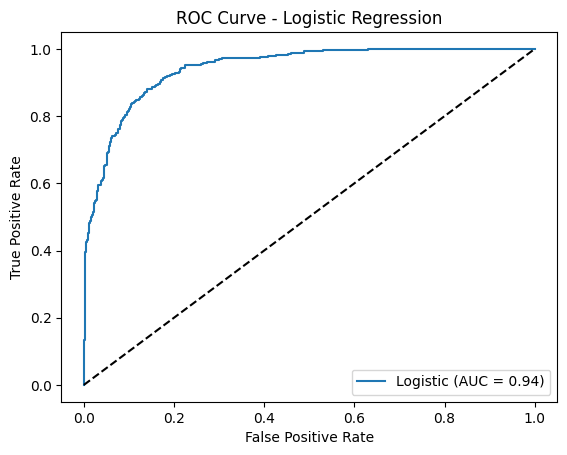

In [52]:
# ROC Curve - plots how well the model seperates the two classes at different thresholds 
# AUC - if closer to 1.0 better model and if 0.5 it is random guessing
# The dotted diagonal line is the baseline 

from sklearn.metrics import roc_curve, auc
# Get probabilities for both the classes and selects probability of class 1 (approved)
y_prob_log = model.predict_proba(X_test)[:, 1]

# Compute ROC
fpr, tpr, thresholds = roc_curve(y_test, y_prob_log)
roc_auc = auc(fpr, tpr)

# Plot
plt.figure()
plt.plot(fpr, tpr, label=f"Logistic (AUC = {roc_auc:.2f})") # plots ROC curve and shows AUC in legend 
plt.plot([0, 1], [0, 1], 'k--') # it draws a diagonal line which reoresents random model 
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Logistic Regression")
plt.legend()
plt.show()

### KNN

In [53]:
# KNN - to predict for a new person, find the 5 most similar people in training data and see what their loan status was 

from sklearn.metrics import accuracy_score
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)

y_pred_knn = knn.predict(X_test)

print("KNN Accuracy:", accuracy_score(y_test, y_pred_knn))

KNN Accuracy: 0.8233333333333334


#### For finding the best neighbour

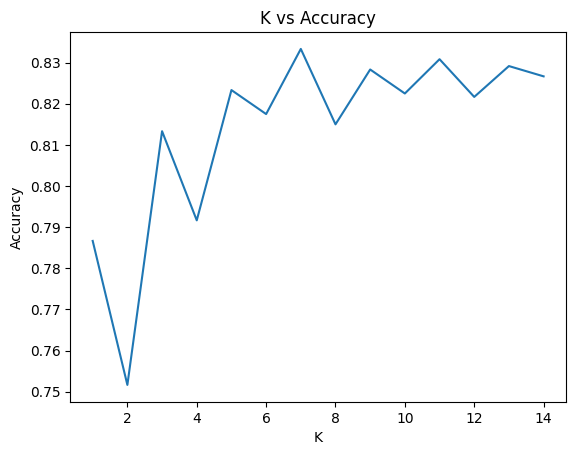

In [54]:
import matplotlib.pyplot as plt

k_values = range(1, 15)
accuracies = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train, y_train) # train model 
    y_pred = knn.predict(X_test) # predict output 
    accuracies.append(accuracy_score(y_test, y_pred))

plt.plot(k_values, accuracies)
plt.xlabel("K")
plt.ylabel("Accuracy")
plt.title("K vs Accuracy")
plt.show()

#### Decision Tree

In [55]:
# Decision Tree - It splits the data based on feature thresholds (like a flowchart)
# At each node it asks a yes/no question about a feature and splits accordingly
# It is interpretable and works well with mixed data types and non-linear patterns

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

dt = DecisionTreeClassifier(max_depth=5, random_state=42)
dt.fit(X_train, y_train) # trains model with learning splits 

y_pred_dt = dt.predict(X_test) # predicts loan status 

print("Decision Tree Accuracy:", accuracy_score(y_test, y_pred_dt))

Decision Tree Accuracy: 0.7983333333333333


Best max_depth: 8 with accuracy 0.8233


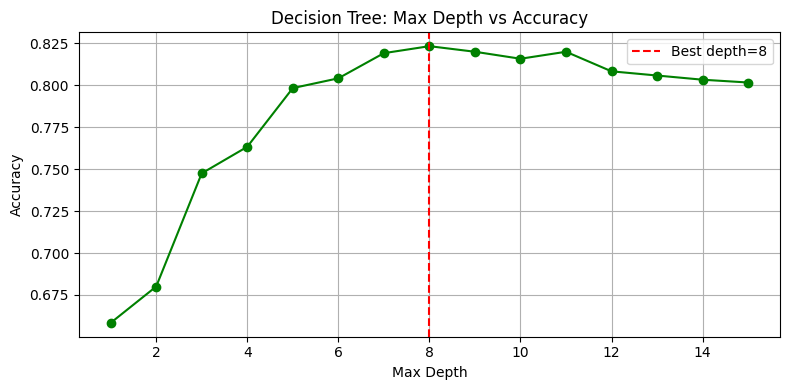

In [56]:
# Finding the best max_depth to avoid overfitting
# A tree that is too deep will memorise the training data (overfit)
# We test depths 1-15 and pick the one with highest test accuracy

depth_values = range(1, 16)
dt_accuracies = []

for d in depth_values:
    dt_temp = DecisionTreeClassifier(max_depth=d, random_state=42)
    dt_temp.fit(X_train, y_train)
    dt_accuracies.append(accuracy_score(y_test, dt_temp.predict(X_test)))

best_depth = list(depth_values)[dt_accuracies.index(max(dt_accuracies))] # find depth with highest accuracy 
print(f"Best max_depth: {best_depth} with accuracy {max(dt_accuracies):.4f}") # print best depth 

plt.figure(figsize=(8, 4))
plt.plot(depth_values, dt_accuracies, marker='o', color='green')
plt.axvline(x=best_depth, color='red', linestyle='--', label=f'Best depth={best_depth}')
plt.xlabel("Max Depth")
plt.ylabel("Accuracy")
plt.title("Decision Tree: Max Depth vs Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

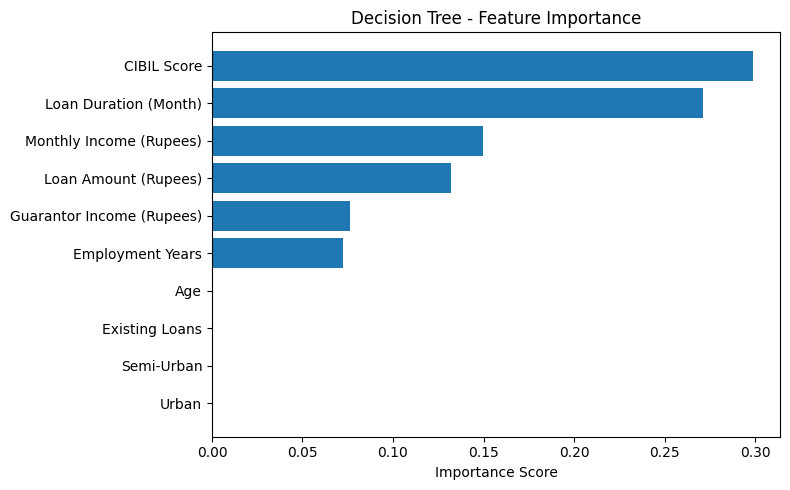

In [57]:
# Feature Importance - Decision Tree tells us which features it found most useful for splitting
# This is one of the biggest advantages of Decision Tree over KNN and Logistic Regression

feature_names = list(X.columns) # get feature names 
importances = dt.feature_importances_ # calculates importance of each feature

feat_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})
feat_df = feat_df.sort_values('Importance', ascending=False)

plt.figure(figsize=(8, 5))
plt.barh(feat_df['Feature'], feat_df['Importance'])   # (kept same, removed color if not required)
plt.xlabel('Importance Score')
plt.title('Decision Tree - Feature Importance')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

#### PCA - Principal Component Analysis

In [58]:
# PCA - reduce number of features while keeping most of the information 
# n_components- keeps enough components to explain 90% of the variance 

from sklearn.decomposition import PCA
pca = PCA(n_components=0.9)

X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)

print("Explained Variance:", pca.explained_variance_ratio_)

Explained Variance: [0.1532228  0.10755105 0.10331505 0.10208135 0.10059145 0.0996709
 0.09797879 0.09536674 0.0932006 ]


#### Model after PCA

In [59]:
model_pca = LogisticRegression()
model_pca.fit(X_train_pca, y_train)

y_pred_pca = model_pca.predict(X_test_pca)

print("Accuracy after PCA:", accuracy_score(y_test, y_pred_pca))

Accuracy after PCA: 0.8658333333333333


#### Comparison between the models

In [60]:
results = {
    "Dummy Classifier": accuracy_score(y_test, y_pred_dummy),
    "Logistic": accuracy_score(y_test, y_pred),
    "KNN": accuracy_score(y_test, y_pred_knn),
    "Decision Tree": accuracy_score(y_test, y_pred_dt),
    "PCA + Logistic": accuracy_score(y_test, y_pred_pca)
}

for model_name, score in results.items():
    print(f"{model_name}: {score:.4f}")

Dummy Classifier: 0.4908
Logistic: 0.8267
KNN: 0.8233
Decision Tree: 0.7983
PCA + Logistic: 0.8658


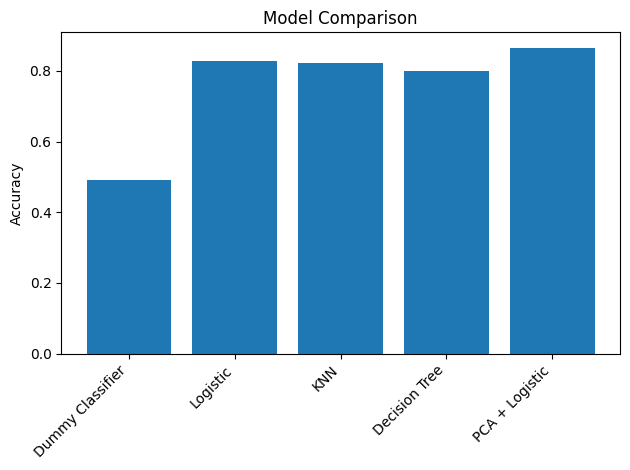

In [61]:
models = list(results.keys())
scores = list(results.values())

plt.bar(models, scores)
plt.title("Model Comparison")
plt.ylabel("Accuracy")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()